# Lab 25.2: Explanation Drift in a Demand Forecast

Run the cells from top to bottom. No code needs to be changed; the questions ask you to read and interpret the results. Each checkpoint says what you should see.

Data: Online Retail II (Chen, 2012), UCI Machine Learning Repository, CC BY 4.0, https://doi.org/10.24432/C5CG6D. About a million invoice lines from a UK online gift retailer, many of whose customers are wholesalers, December 2009 to December 2011. We forecast next week's units for each of about a thousand products and watch the forecast in production for 64 weeks.

This notebook reproduces the data case study of Chapter 25 and its Figures 25.3 to 25.5.

In [1]:
import os, pathlib, tempfile, zipfile, urllib.request, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import GradientBoostingRegressor
warnings.filterwarnings("ignore")
print("shap", shap.__version__)
T0 = time.time()

shap 0.49.1


## 1. Load the data

If you set the environment variable `ONLINE_RETAIL_II` to a local `online_retail_II.xlsx` (or a `.csv.gz` export), it is used. Otherwise the zip file (about 45 MB) is downloaded once from UCI into a temporary folder. Reading the Excel file takes about a minute.

In [2]:
UCI = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
def load():
    path = os.environ.get("ONLINE_RETAIL_II")
    if not path:
        cache = pathlib.Path(tempfile.gettempdir()) / "xai-ch25"; cache.mkdir(exist_ok=True)
        path = cache / "online_retail_II.xlsx"
        if not path.exists():
            z = cache / "oretail.zip"; urllib.request.urlretrieve(UCI, z); zipfile.ZipFile(z).extractall(cache)
    path = str(path)
    if path.endswith(".xlsx"):
        return pd.concat(pd.read_excel(path, sheet_name=None, dtype={"Invoice": str, "StockCode": str}).values(), ignore_index=True)
    return pd.read_csv(path, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
raw = load()
print(len(raw), "invoice lines")

1067371 invoice lines


## 2. Build the forecasting table

One row per product and week. Features are known at the end of week *t*; the target is log(1 + units sold) in week *t* + 1. Cancellations are removed. Products sold in at least 70 of the 105 full weeks are kept.

| Feature | Meaning |
|---|---|
| `last_week` | log(1 + units) in week *t* |
| `two_weeks_ago` | the same, one week earlier |
| `four_week_mean`, `twelve_week_mean` | rolling means of the log units |
| `customers_last_week` | log(1 + distinct customers buying the product in week *t*) |
| `price_vs_usual` | median price in week *t* divided by the product's 12-week median |
| `store_orders_last_week` | log of all invoices in the store in week *t* (the same for every product) |
| `month` | month of the forecast week |

In [3]:
FEATS = ["last_week", "two_weeks_ago", "four_week_mean", "twelve_week_mean",
         "customers_last_week", "price_vs_usual", "store_orders_last_week", "month"]
PRODUCT_LEVEL = FEATS[:6]
d = raw[~raw.Invoice.str.startswith("C") & (raw.Quantity > 0) & (raw.Price > 0)].copy()
d["week"] = d.InvoiceDate.dt.to_period("W-SUN").dt.start_time
weeks = pd.date_range("2009-11-30", "2011-11-28", freq="7D")
d = d[d.week.isin(weeks)]
cnt = d.groupby("StockCode").week.nunique(); prods = cnt[cnt >= 70].index
g = d[d.StockCode.isin(prods)].groupby(["StockCode", "week"]).agg(q=("Quantity", "sum"), cust=("Customer ID", "nunique"), price=("Price", "median"))
g = g.reindex(pd.MultiIndex.from_product([prods, weeks], names=["StockCode", "week"]))
g["q"] = g.q.fillna(0); g["cust"] = g.cust.fillna(0); g["price"] = g.groupby(level=0).price.ffill().bfill()
store = d.groupby("week").Invoice.nunique().reindex(weeks)
g = g.reset_index(); g["lq"] = np.log1p(g.q); gb = g.groupby("StockCode")
F = pd.DataFrame({"StockCode": g.StockCode, "week": g.week})
F["last_week"] = g.lq
F["two_weeks_ago"] = gb.lq.shift(1)
F["four_week_mean"] = gb.lq.transform(lambda s: s.rolling(4).mean())
F["twelve_week_mean"] = gb.lq.transform(lambda s: s.rolling(12).mean())
F["customers_last_week"] = np.log1p(g.cust)
F["price_vs_usual"] = g.price / gb.price.transform(lambda s: s.rolling(12, min_periods=4).median())
F["store_orders_last_week"] = np.log(g.week.map(store))
F["month"] = (g.week + pd.Timedelta(days=7)).dt.month
F["target"] = gb.lq.shift(-1)
F = F.dropna().reset_index(drop=True)
print(len(prods), "products;", len(F), "product-weeks")

1061 products; 97612 product-weeks


**Checkpoint 1:** 1,061 products.

## 3. Train the launch model and record its reference explanation

The model is trained on forecast weeks from 22 February to 23 August 2010, so it has never seen a holiday season. The reference explanation is the share of mean absolute TreeSHAP attribution for each feature on 3,000 training rows. We also measure how much the weekly shares move *inside* the training period: that natural variation sets the alarm threshold.

In [4]:
def gbr():
    return GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=0)
def shares(phi):
    s = np.abs(phi).mean(0); return s / s.sum()
trA = F[(F.week >= "2010-02-22") & (F.week <= "2010-08-23")]
mA = gbr().fit(trA[FEATS], trA.target); exA = shap.TreeExplainer(mA)
share_ref = shares(exA.shap_values(trA.sample(3000, random_state=0)[FEATS]))
train_mae = np.mean(np.abs(mA.predict(trA[FEATS]) - trA.target))
tv_train = [0.5 * np.abs(shares(exA.shap_values(p[FEATS])) - share_ref).sum() for _, p in trA.groupby("week")]
TH = np.quantile(tv_train, 0.95)
print(len(trA), "training rows; training MAE %.3f" % train_mae)
print(pd.Series(share_ref, index=FEATS).round(3))
print("alarm threshold (95th percentile of weekly shifts in training): %.3f" % TH)

28647 training rows; training MAE 0.839
last_week                 0.165
two_weeks_ago             0.068
four_week_mean            0.378
twelve_week_mean          0.125
customers_last_week       0.164
price_vs_usual            0.014
store_orders_last_week    0.052
month                     0.033
dtype: float64
alarm threshold (95th percentile of weekly shifts in training): 0.107


**Checkpoint 2:** 28,647 training rows; training MAE about 0.84 (log units); the 4-week average holds about 0.38 of the attribution; the threshold is about 0.107.

## 4. Watch 64 weeks in production

For each week we compute three monitors: input drift (the population stability index, PSI, of each product-level feature against training), explanation drift (total variation distance between this week's attribution shares and the reference), and the error, which in real life arrives a week later.

In [5]:
def psi(ref, cur, bins=10):
    qs = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); qs[0], qs[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, qs)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, qs)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))
smin = trA.store_orders_last_week.min()
mon = F[F.week > "2010-08-23"]
rows = []
for wk, part in mon.groupby("week"):
    X, y = part[FEATS], part.target.values
    sh = shares(exA.shap_values(X))
    rows.append(dict(week=wk, mae=np.mean(np.abs(mA.predict(X) - y)), tv=0.5 * np.abs(sh - share_ref).sum(),
                     store_share=sh[6], below_range=X.store_orders_last_week.iloc[0] < smin,
                     n_psi=sum(psi(trA[f].values, X[f].values) > 0.25 for f in PRODUCT_LEVEL)))
M = pd.DataFrame(rows)
M["flag"] = M.tv > TH
print(M.round(3).to_string())

         week    mae     tv  store_share  below_range  n_psi   flag
0  2010-08-30  0.865  0.055        0.020        False      0  False
1  2010-09-06  0.863  0.053        0.081        False      0  False
2  2010-09-13  0.925  0.043        0.079        False      0  False
3  2010-09-20  0.947  0.038        0.015        False      0  False
4  2010-09-27  0.918  0.047        0.013        False      0  False
5  2010-10-04  0.853  0.051        0.013        False      0  False
6  2010-10-11  0.769  0.059        0.012        False      0  False
7  2010-10-18  0.798  0.057        0.013        False      0  False
8  2010-10-25  0.805  0.048        0.014        False      0  False
9  2010-11-01  0.797  0.044        0.013        False      0  False
10 2010-11-08  0.774  0.049        0.013        False      1  False
11 2010-11-15  0.667  0.053        0.012        False      2  False
12 2010-11-22  0.889  0.058        0.012        False      3  False
13 2010-11-29  0.807  0.057        0.011        

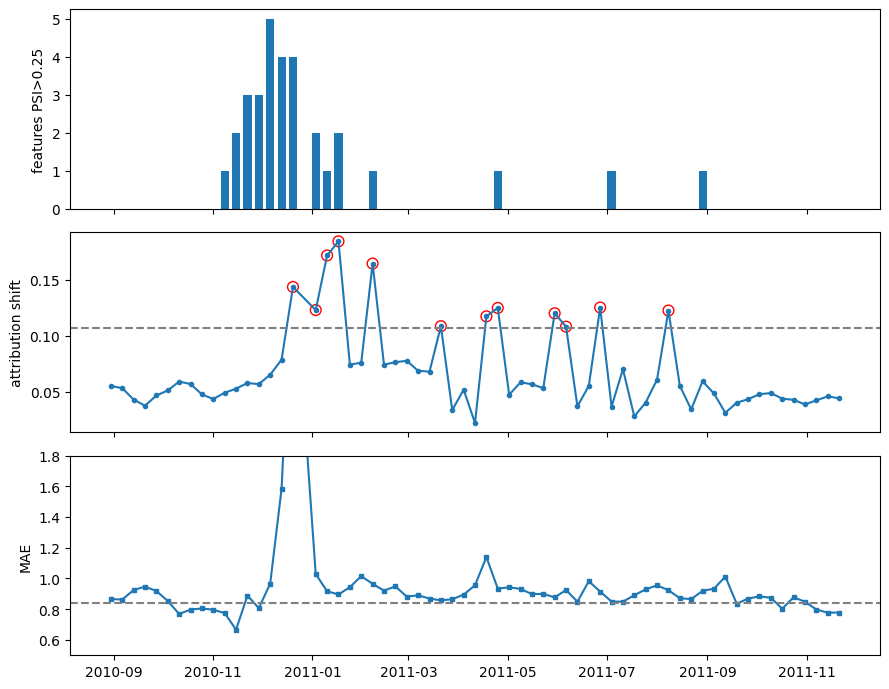

weeks flagged: 12 of 64
flagged weeks with store orders below the training minimum (279 orders): 9
store-orders share in flagged weeks: 0.101 to 0.161 (reference 0.052)
weeks with at least one PSI alarm: 14
MAE flagged 1.126, unflagged 0.891, November 2010 0.787


In [6]:
fig, axs = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axs[0].bar(M.week, M.n_psi, width=5); axs[0].set_ylabel("features PSI>0.25")
axs[1].plot(M.week, M.tv, marker="o", ms=3); axs[1].axhline(TH, ls="--", color="gray")
axs[1].scatter(M.week[M.flag], M.tv[M.flag], s=60, facecolor="none", edgecolor="red"); axs[1].set_ylabel("attribution shift")
axs[2].plot(M.week, M.mae, marker="s", ms=3); axs[2].axhline(train_mae, ls="--", color="gray"); axs[2].set_ylim(0.5, 1.8); axs[2].set_ylabel("MAE")
plt.tight_layout(); plt.show()
fl = M[M.flag]
print("weeks flagged:", len(fl), "of", len(M))
print("flagged weeks with store orders below the training minimum (%d orders): %d" % (round(np.exp(smin)), fl.below_range.sum()))
print("store-orders share in flagged weeks: %.3f to %.3f (reference %.3f)" % (fl.store_share.min(), fl.store_share.max(), share_ref[6]))
print("weeks with at least one PSI alarm: %d" % (M.n_psi >= 1).sum())
print("MAE flagged %.3f, unflagged %.3f, November 2010 %.3f" % (fl.mae.mean(), M[~M.flag].mae.mean(),
      M[(M.week >= "2010-11-01") & (M.week <= "2010-11-29")].mae.mean()))

**Checkpoint 3:** 12 of 64 weeks flagged; in 9 of them the store's weekly orders were below anything seen in training (279); in every flagged week store orders took between about 0.10 and 0.16 of the attribution, against 0.05 in the reference. Input drift alarms cluster in November and December 2010, when the November error was *lower* than in training (about 0.79). The worst error, 3.13 in the week of 20 December 2010, is flagged; the forecast made in the week of 13 December for the Christmas closure (error 1.58) is not.

**Question A.** Why can no monitor that looks only at this week's inputs and explanations warn you about the forecast for the closure week? What would?

## 5. A silent bug: a stale feature

We now simulate a pipeline bug in the spirit of Lundberg et al. (2020), who swapped two operating-room labels in a hospital model to mimic a feature pipeline bug. From 6 June 2011 the feature store stops updating `four_week_mean`: every product keeps the value it had that week. We compare three monitors for this feature, with and without the bug. The third, *loss attribution*, is how much the week's error grows when the feature is shuffled; it needs the labels.

In [7]:
BUG = pd.Timestamp("2011-06-06")
frozen = mon[mon.week == BUG].set_index("StockCode")["four_week_mean"]
rng = np.random.default_rng(0)
def perm_loss(X, y, f, reps=3):
    base = np.mean(np.abs(mA.predict(X) - y)); out = []
    for _ in range(reps):
        Xp = X.copy(); Xp[f] = rng.permutation(Xp[f].values); out.append(np.mean(np.abs(mA.predict(Xp) - y)) - base)
    return np.mean(out)
rows = []
for wk, part in mon[mon.week >= "2011-03-01"].groupby("week"):
    X, y = part[FEATS], part.target.values
    Xb = X.copy()
    if wk >= BUG:
        Xb["four_week_mean"] = part.StockCode.map(frozen).fillna(part.four_week_mean).values
    rows.append(dict(week=wk, psi_ok=psi(trA.four_week_mean.values, X.four_week_mean.values),
                     psi_bug=psi(trA.four_week_mean.values, Xb.four_week_mean.values),
                     share_ok=shares(exA.shap_values(X))[2], share_bug=shares(exA.shap_values(Xb))[2],
                     loss_ok=perm_loss(X, y, "four_week_mean"), loss_bug=perm_loss(Xb, y, "four_week_mean"),
                     mae_ok=np.mean(np.abs(mA.predict(X) - y)), mae_bug=np.mean(np.abs(mA.predict(Xb) - y))))
S = pd.DataFrame(rows)
late = S[S.week >= "2011-10-01"]
print(late[["psi_bug", "share_ok", "share_bug", "loss_ok", "loss_bug", "mae_ok", "mae_bug"]].mean().round(3))
print("max PSI with the bug: %.3f" % S[S.week >= BUG].psi_bug.max())

psi_bug      0.052
share_ok     0.394
share_bug    0.349
loss_ok      0.311
loss_bug     0.129
mae_ok       0.830
mae_bug      0.971
dtype: float64
max PSI with the bug: 0.052


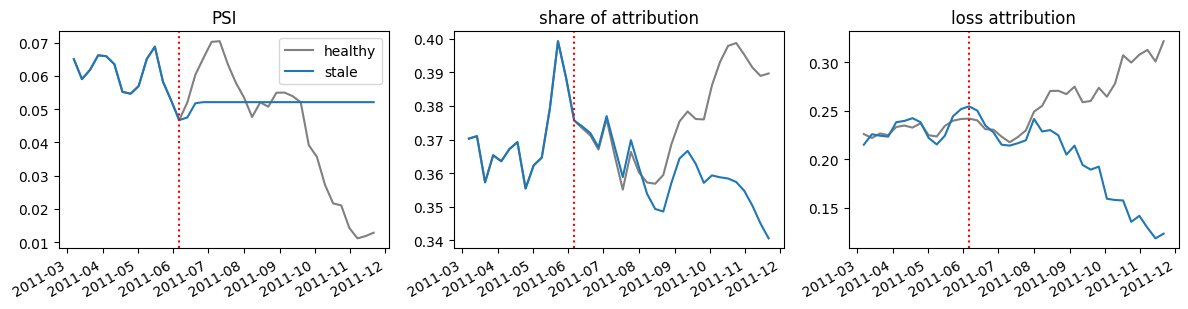

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (a, b, t) in zip(axs, [("psi_ok", "psi_bug", "PSI"), ("share_ok", "share_bug", "share of attribution"), ("loss_ok", "loss_bug", "loss attribution")]):
    ax.plot(S.week, S[a].rolling(4, min_periods=1).mean(), color="gray", label="healthy")
    ax.plot(S.week, S[b].rolling(4, min_periods=1).mean(), label="stale"); ax.axvline(BUG, ls=":", color="red"); ax.set_title(t)
axs[0].legend(); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

**Checkpoint 4:** with the bug, the PSI of the 4-week average stays near 0.05 (no alarm), its share of the prediction attributions stays about 0.35 (no alarm), but from October 2011 its loss attribution is about 0.13 against about 0.31 in the healthy run, and the error is about 0.97 against 0.83.

**Question B.** Which monitor needs labels, and how long would you have waited for this signal in a business where outcomes arrive after 90 days?

## 6. Retraining: same accuracy, different reasons

In late January 2011 the team retrains on everything up to 24 January 2011, including the 2010 holiday season. Both models now explain the same 18,037 product-weeks from February to May 2011.

In [9]:
trB = F[(F.week >= "2010-02-22") & (F.week <= "2011-01-24")]
mB = gbr().fit(trB[FEATS], trB.target); exB = shap.TreeExplainer(mB)
ev = F[(F.week >= "2011-02-07") & (F.week <= "2011-05-30")]
A, B = exA.shap_values(ev[FEATS]), exB.shap_values(ev[FEATS])
print("MAE launch %.3f, retrained %.3f" % (np.mean(np.abs(mA.predict(ev[FEATS]) - ev.target)), np.mean(np.abs(mB.predict(ev[FEATS]) - ev.target))))
print(pd.DataFrame({"launch": shares(A), "retrained": shares(B)}, index=FEATS).round(3))
ta, tb = np.argmax(np.abs(A), 1), np.argmax(np.abs(B), 1)
print("top reason changed for %.1f percent of %d product-weeks" % (100 * np.mean(ta != tb), len(ev)))
names = dict(enumerate(FEATS))
print(pd.crosstab(pd.Series(ta).map(names).rename("launch"), pd.Series(tb).map(names).rename("retrained")))
print("minutes so far: %.1f" % ((time.time() - T0) / 60))

MAE launch 0.922, retrained 0.923
                        launch  retrained
last_week                0.157      0.229
two_weeks_ago            0.076      0.080
four_week_mean           0.364      0.276
twelve_week_mean         0.120      0.129
customers_last_week      0.155      0.145
price_vs_usual           0.022      0.018
store_orders_last_week   0.065      0.059
month                    0.042      0.064
top reason changed for 31.3 percent of 18037 product-weeks
retrained               customers_last_week  four_week_mean  last_week  month  \
launch                                                                          
customers_last_week                     725              59        380      7   
four_week_mean                          480           10272       3126     31   
last_week                                 3              31        741      0   
month                                     0               7         20     22   
price_vs_usual                            6

**Checkpoint 5:** errors of 0.922 and 0.923; the 4-week average falls from about 0.36 to 0.28 of the attribution and last week's units rise from about 0.16 to 0.23; the top reason changes for about 31 percent of product-weeks, most often from the 4-week average to last week's units.

**Question C.** A store manager was told last month that the 4-week trend drove her reorder suggestions. After retraining, most of her suggestions name last week's sales. Write the two-sentence release note she should receive, and the acceptance test you would add before the next retraining.

## What to hand in

The three monitoring results (sections 4 to 6) with your answers to Questions A to C, and a half-page monitoring plan for this forecast: which monitors, which thresholds and how you set them, who is alerted, and what they do.